# Phase 10.1 - Leak-safe Decision Engine (GBPUSD)

Entrena el modelo base por cada fold temporal (solo pasado), genera señales out-of-fold y evalúa la política con costos.

In [1]:
from pathlib import Path
import subprocess

ROOT = Path('.')
SCRIPT = ROOT / 'phases/phase10_decision_engine/run_phase10_1_decision_engine_leak_safe.py'

res = subprocess.run(['python', str(SCRIPT)], cwd=ROOT, check=True, capture_output=True, text=True)
print(res.stdout)
if res.stderr:
    print(res.stderr)


Saved summary: ./phases/phase10_decision_engine/output_phase10_1_leak_safe_GBPUSD/GBPUSD_phase10_1_summary.json
Walk-forward mean metrics:
{'fold': 3.0, 'train_rows': 15557.0, 'test_rows': 2396.0, 'phase9_thr': 0.5, 'policy_conf_thr': 0.48, 'policy_inf_min': 0.33999999999999997, 'policy_calib_score': 1.9297165859174057, 'acc_action_3': 0.2832220367278798, 'f1_macro_action_3': 0.2677525804255908, 'avg_net_return': 0.00012396168982915874, 'cum_net_return': 0.29701220883066437, 'std_net_return': 0.003061571210828084, 'sharpe_ann': 3.296727053504779, 'trade_rate': 0.2631051689386368, 'win_rate_trades': 0.5850816062463133}



In [2]:
import json
import pandas as pd
from IPython.display import display

OUT = ROOT / 'phases/phase10_decision_engine/output_phase10_1_leak_safe_GBPUSD'
summary = json.loads((OUT / 'GBPUSD_phase10_1_summary.json').read_text())
metrics = pd.read_csv(OUT / 'GBPUSD_phase10_1_walkforward_metrics.csv')
phase9_folds = pd.read_csv(OUT / 'GBPUSD_phase10_1_phase9_fold_metrics.csv')
preds = pd.read_csv(OUT / 'GBPUSD_phase10_1_fold_predictions.csv')

print('Dataset:', summary['dataset'])
print('Walk-forward mean metrics:')
display(pd.Series(summary['walkforward']['mean_metrics']).to_frame('mean'))
print('Decision fold metrics:')
display(metrics)
print('Phase9 fold metrics:')
display(phase9_folds)
print('Action distribution test folds:')
display(preds['pred_action'].value_counts().sort_index())


Dataset: {'n_rows': 23967, 'date_min': '2000-05-31 10:00:00', 'date_max': '2025-10-29 19:00:00', 'target_action_dist': {'-1': 10186, '0': 3768, '1': 10013}}
Walk-forward mean metrics:


,mean
fold,3.000000
train_rows,15557.000000
test_rows,2396.000000
phase9_thr,0.500000
policy_conf_thr,0.480000
policy_inf_min,0.340000
policy_calib_score,1.929717
acc_action_3,0.283222
f1_macro_action_3,0.267753
avg_net_return,0.000124


Decision fold metrics:


,fold,train_rows,test_rows,timestamp_test_start,timestamp_test_end,phase9_thr,policy_conf_thr,policy_inf_min,policy_calib_score,acc_action_3,f1_macro_action_3,avg_net_return,cum_net_return,std_net_return,sharpe_ann,trade_rate,win_rate_trades
0,1,10765,2396,2010-01-27 04:00:00,2011-10-26 10:00:00,0.525,0.55,0.3,2.532086,0.189482,0.164356,0.000075,0.180778,0.001752,3.349594,0.095159,0.614035
1,2,13161,2396,2011-10-26 11:00:00,2016-02-03 02:00:00,0.475,0.40,0.3,1.413575,0.361853,0.353515,0.000082,0.197477,0.003300,1.942356,0.354341,0.545347
2,3,15557,2396,2016-02-03 03:00:00,2018-02-05 03:00:00,0.500,0.40,0.3,1.630734,0.370618,0.368183,0.000300,0.717827,0.005092,4.575401,0.422371,0.539526
3,4,17953,2396,2018-02-05 04:00:00,2020-09-22 03:00:00,0.525,0.40,0.5,2.660573,0.346828,0.346320,0.000089,0.214419,0.004002,1.738911,0.414441,0.540785
4,5,20349,2396,2020-09-22 04:00:00,2023-06-01 11:00:00,0.475,0.65,0.3,1.411616,0.147329,0.106389,0.000073,0.174561,0.001162,4.877373,0.029215,0.685714


Phase9 fold metrics:


,fold,best_score,thr,score,acc,f1_macro_all,f1_macro_informative,recall_class0,mae_progress,rmse_progress,mae_progress_early
0,1,0.469024,0.525,0.469024,0.565675,0.334073,0.180998,0.812620,0.079727,0.095440,0.054988
1,2,0.445859,0.475,0.445859,0.589159,0.308858,0.148649,0.793203,0.049407,0.069090,0.035432
2,3,0.474422,0.500,0.474422,0.650236,0.331846,0.217287,0.742770,0.051847,0.055674,0.045367
3,4,0.470706,0.525,0.470706,0.693165,0.350164,0.167525,0.860266,0.092068,0.103418,0.078340
4,5,0.421760,0.475,0.421760,0.513106,0.315330,0.213161,0.648539,0.099046,0.122840,0.073066


Action distribution test folds:


pred_action
-1    1613
 0    8828
 1    1539
Name: count, dtype: int64

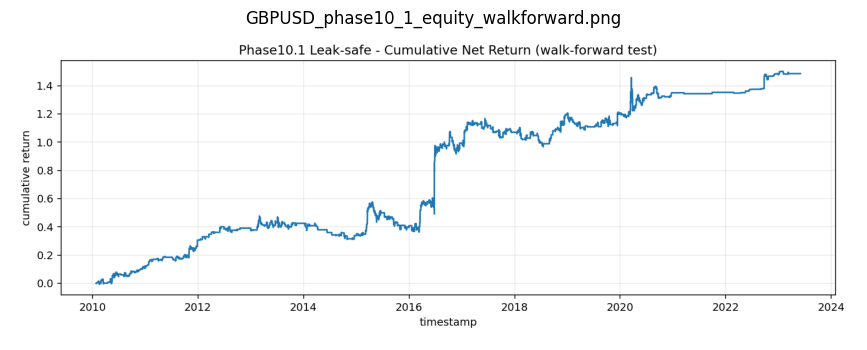

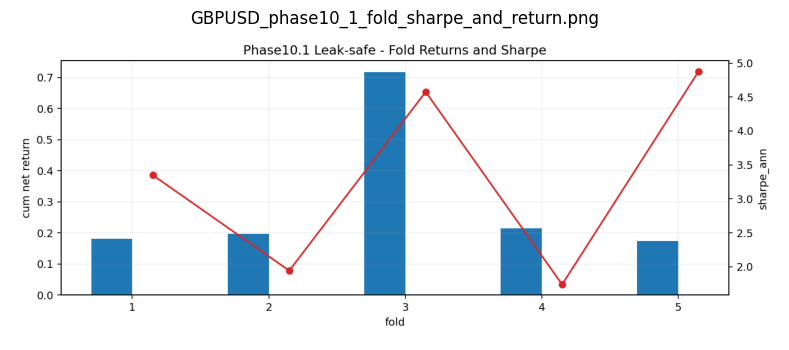

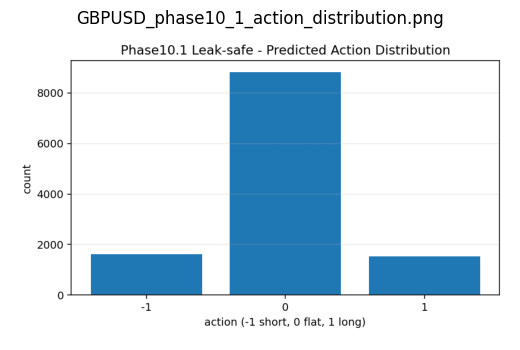

In [3]:
import matplotlib.pyplot as plt

img_paths = [
    OUT / 'GBPUSD_phase10_1_equity_walkforward.png',
    OUT / 'GBPUSD_phase10_1_fold_sharpe_and_return.png',
    OUT / 'GBPUSD_phase10_1_action_distribution.png',
]

for p in img_paths:
    img = plt.imread(p)
    plt.figure(figsize=(12, 4))
    plt.imshow(img)
    plt.title(p.name)
    plt.axis('off')
    plt.show()
